# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
vocab_size = 10000
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.reuters.load_data(num_words=vocab_size)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


In [3]:
print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)

(8982,) (8982,)
(2246,) (2246,)


In [4]:
num_classes = len(np.unique(y_train_full))
num_classes

46

In [5]:
word_index = keras.datasets.reuters.get_word_index()
index_word = {i + 3: w for w, i in word_index.items()}
index_word.update({0: '<PAD>', 1: '<START>', 2: '<UNK>'})

print(' '.join(index_word.get(i, '?') for i in X_train_full[0]))
print('Topic:', y_train_full[0])

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 1s 2us/step
<START> <UNK> <UNK> said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3
Topic: 3


In [6]:
lengths = pd.Series([len(x) for x in X_train_full])
lengths.describe()

,0
count,8982.000000
mean,145.539857
std,145.822248
min,13.000000
25%,60.000000
50%,95.000000
75%,179.000000
max,2376.000000


In [7]:
(lengths > 200).mean() * 100

np.float64(20.875083500334)

In [8]:
pd.Series(y_train_full).value_counts().head(10)

,count
3,3159
4,1949
19,549
16,444
1,432
11,390
20,269
13,172
8,139
10,124


In [9]:
pd.Series(y_train_full).value_counts().tail(10)

,count
29,19
45,18
5,17
7,16
22,15
27,15
42,13
44,12
33,11
35,10


# ***Data Visualization***

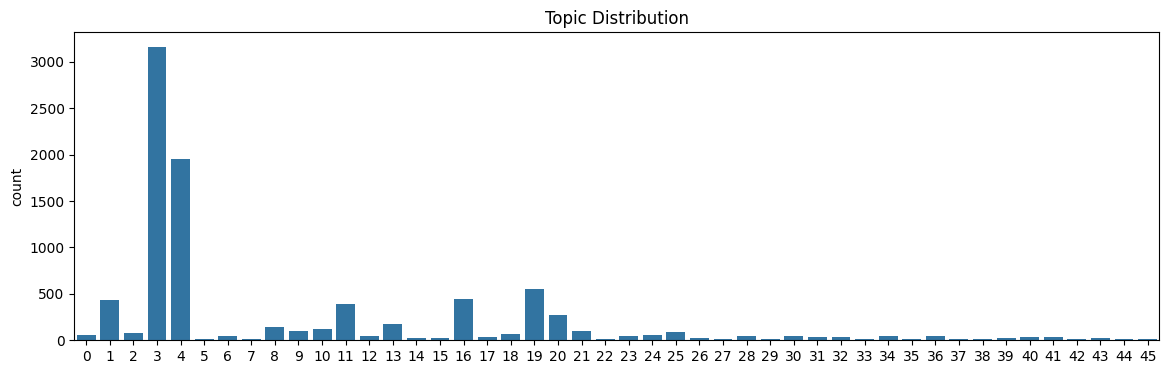

In [10]:
plt.figure(figsize=(14, 4))
sns.countplot(x=y_train_full)
plt.title('Topic Distribution')
plt.show()

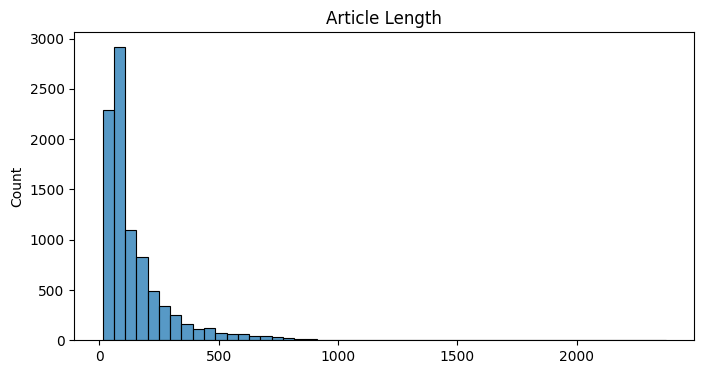

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(lengths, bins=50)
plt.title('Article Length')
plt.show()

# ***Data Preprocessing***

In [12]:
maxlen = 200

X_train_full = keras.utils.pad_sequences(X_train_full, maxlen=maxlen)
X_test = keras.utils.pad_sequences(X_test, maxlen=maxlen)
X_train_full.shape

(8982, 200)

In [13]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(8083, 200) (899, 200) (2246, 200)


# ***ANN Model***

In [14]:
ann_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 64),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 647,150 (2.47 MB)

 Trainable params: 647,150 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

ann_history = ann_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/30
127/127 - 7s - 52ms/step - accuracy: 0.3768 - loss: 2.5793 - val_accuracy: 0.4605 - val_loss: 2.1346
Epoch 2/30
127/127 - 1s - 5ms/step - accuracy: 0.4716 - loss: 2.0691 - val_accuracy: 0.5106 - val_loss: 1.9149
Epoch 3/30
127/127 - 1s - 5ms/step - accuracy: 0.5220 - loss: 1.8869 - val_accuracy: 0.5562 - val_loss: 1.7582
Epoch 4/30
127/127 - 1s - 5ms/step - accuracy: 0.5718 - loss: 1.7105 - val_accuracy: 0.5996 - val_loss: 1.5915
Epoch 5/30
127/127 - 1s - 5ms/step - accuracy: 0.6365 - loss: 1.5356 - val_accuracy: 0.6440 - val_loss: 1.4657
Epoch 6/30
127/127 - 1s - 4ms/step - accuracy: 0.6687 - loss: 1.3921 - val_accuracy: 0.6618 - val_loss: 1.3605
Epoch 7/30
127/127 - 1s - 4ms/step - accuracy: 0.6902 - loss: 1.2770 - val_accuracy: 0.6808 - val_loss: 1.2817
Epoch 8/30
127/127 - 1s - 4ms/step - accuracy: 0.7060 - loss: 1.1910 - val_accuracy: 0.6974 - val_loss: 1.2255
Epoch 9/30
127/127 - 1s - 4ms/step - accuracy: 0.7206 - loss: 1.1157 - val_accuracy: 0.7041 - val_loss: 1.1838


# ***LSTM Model***

In [16]:
lstm_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 64),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,014 (2.58 MB)

 Trainable params: 676,014 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

lstm_history = lstm_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/30
127/127 - 7s - 56ms/step - accuracy: 0.3819 - loss: 2.5252 - val_accuracy: 0.4883 - val_loss: 2.0608
Epoch 2/30
127/127 - 1s - 11ms/step - accuracy: 0.4381 - loss: 2.2268 - val_accuracy: 0.4305 - val_loss: 2.1916
Epoch 3/30
127/127 - 1s - 11ms/step - accuracy: 0.4694 - loss: 2.0597 - val_accuracy: 0.5306 - val_loss: 1.9277
Epoch 4/30
127/127 - 2s - 14ms/step - accuracy: 0.5394 - loss: 1.8053 - val_accuracy: 0.5117 - val_loss: 1.7958
Epoch 5/30
127/127 - 2s - 15ms/step - accuracy: 0.5404 - loss: 1.7104 - val_accuracy: 0.5606 - val_loss: 1.6809
Epoch 6/30
127/127 - 2s - 17ms/step - accuracy: 0.5708 - loss: 1.5905 - val_accuracy: 0.5784 - val_loss: 1.6196
Epoch 7/30
127/127 - 1s - 11ms/step - accuracy: 0.5921 - loss: 1.4797 - val_accuracy: 0.5862 - val_loss: 1.5995
Epoch 8/30
127/127 - 1s - 12ms/step - accuracy: 0.6149 - loss: 1.3879 - val_accuracy: 0.6018 - val_loss: 1.6083
Epoch 9/30
127/127 - 1s - 11ms/step - accuracy: 0.6498 - loss: 1.2745 - val_accuracy: 0.6140 - val_loss:

# ***Bidirectional LSTM Model***

In [18]:
bilstm_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 64),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

bilstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
bilstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 711,982 (2.72 MB)

 Trainable params: 711,982 (2.72 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

bilstm_history = bilstm_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/30
127/127 - 4s - 33ms/step - accuracy: 0.4050 - loss: 2.3627 - val_accuracy: 0.4060 - val_loss: 2.2509
Epoch 2/30
127/127 - 2s - 17ms/step - accuracy: 0.5213 - loss: 1.8479 - val_accuracy: 0.5362 - val_loss: 1.7888
Epoch 3/30
127/127 - 2s - 17ms/step - accuracy: 0.5714 - loss: 1.6694 - val_accuracy: 0.5395 - val_loss: 1.7630
Epoch 4/30
127/127 - 3s - 23ms/step - accuracy: 0.5948 - loss: 1.5596 - val_accuracy: 0.5940 - val_loss: 1.5758
Epoch 5/30
127/127 - 2s - 17ms/step - accuracy: 0.6416 - loss: 1.4150 - val_accuracy: 0.6229 - val_loss: 1.5055
Epoch 6/30
127/127 - 2s - 17ms/step - accuracy: 0.6724 - loss: 1.2606 - val_accuracy: 0.5895 - val_loss: 1.6055
Epoch 7/30
127/127 - 2s - 18ms/step - accuracy: 0.6842 - loss: 1.1995 - val_accuracy: 0.6085 - val_loss: 1.5379
Epoch 8/30
127/127 - 2s - 18ms/step - accuracy: 0.7082 - loss: 1.0826 - val_accuracy: 0.6218 - val_loss: 1.5357


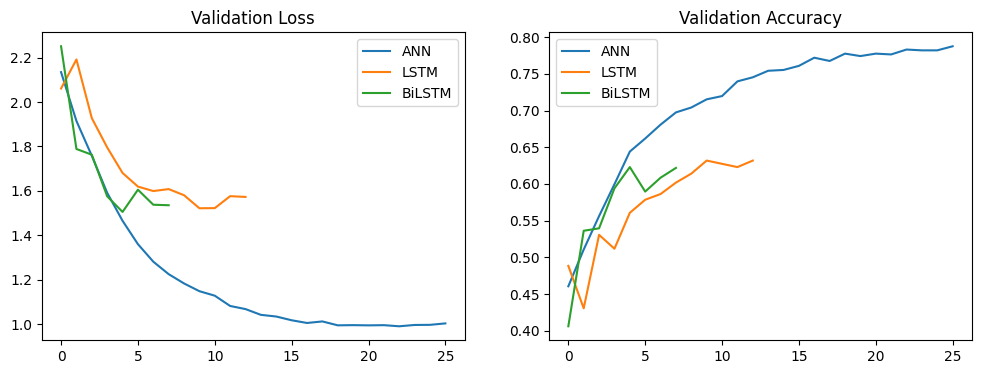

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ann_history.history['val_loss'], label='ANN')
plt.plot(lstm_history.history['val_loss'], label='LSTM')
plt.plot(bilstm_history.history['val_loss'], label='BiLSTM')
plt.title('Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ann_history.history['val_accuracy'], label='ANN')
plt.plot(lstm_history.history['val_accuracy'], label='LSTM')
plt.plot(bilstm_history.history['val_accuracy'], label='BiLSTM')
plt.title('Validation Accuracy')
plt.legend()

plt.show()

# ***Evaluating the Bidirectional LSTM***

In [21]:
y_pred_bilstm = np.argmax(bilstm_model.predict(X_test, verbose=0), axis=1)
print("Accuracy:", accuracy_score(y_test, y_pred_bilstm))

Accuracy: 0.6166518254674977


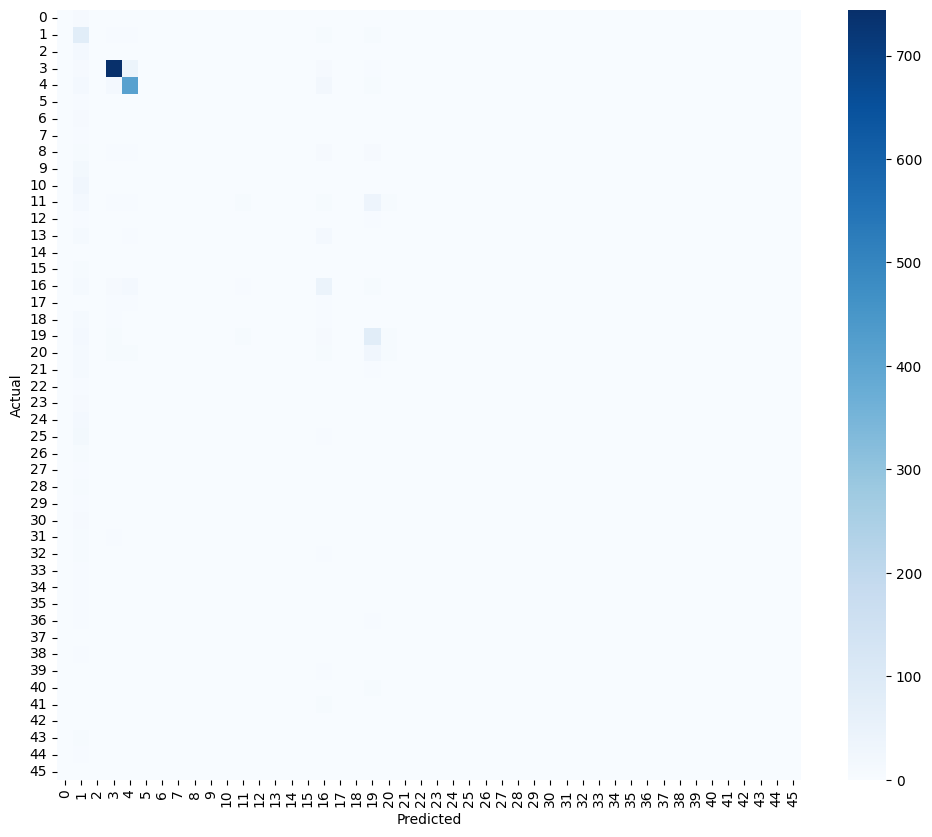

In [22]:
cm = confusion_matrix(y_test, y_pred_bilstm)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [23]:
acc_per_class = pd.Series(cm.diagonal() / cm.sum(axis=1)).sort_values()
acc_per_class.head(10)

,0
0,0.0
2,0.0
6,0.0
5,0.0
7,0.0
10,0.0
9,0.0
8,0.0
14,0.0
13,0.0


# ***Model Comparison***

In [24]:
y_pred_ann = np.argmax(ann_model.predict(X_test, verbose=0), axis=1)
y_pred_lstm = np.argmax(lstm_model.predict(X_test, verbose=0), axis=1)

results = []
for name, y_pred in [("ANN", y_pred_ann), ("LSTM", y_pred_lstm), ("BiLSTM", y_pred_bilstm)]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average='macro', zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Accuracy", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Accuracy,Precision,Recall,F1 (macro),F1 (weighted)
0,ANN,0.771594,0.382941,0.316966,0.327767,0.746658
1,LSTM,0.619323,0.084567,0.104277,0.089592,0.584110
2,BiLSTM,0.616652,0.064718,0.084017,0.067650,0.572714


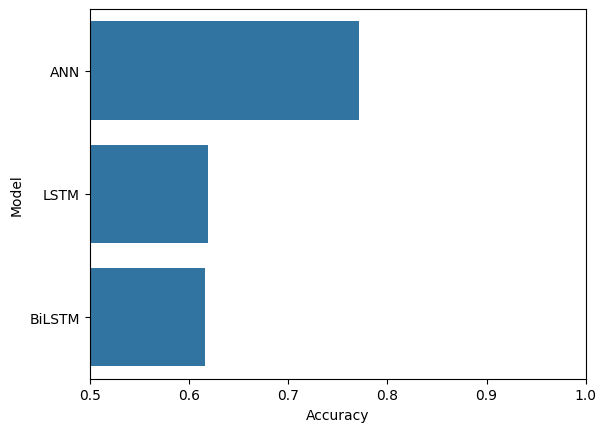

In [25]:
sns.barplot(x="Accuracy", y="Model", data=results_df)
plt.xlim(0.5, 1.0)
plt.show()

# ***Saving the Model***

In [26]:
bilstm_model.save("reuters_bilstm.keras")
joblib.dump(word_index, "word_index.pkl")

['word_index.pkl']